# 08 · Counterfactual explanations for individual fault runs

**Objective.** For each held-out fault run, answer: *which minimal set of maintenance actions, taken when the model detected the problem, would have kept the alarms from firing in this run?* Then evaluate those explanations.

**Population intervention vs individual counterfactual.** Notebook 07 asked what happens *on average* under do(X = x). A counterfactual asks about **this run**, with everything else that happened in it held fixed. It uses Pearl's three steps:

1. **Abduction:** infer the noise $U_j[t]$ of every variable and step that is consistent with the observed run. With the uniform-threshold equation, an observed $x_j[t]=1$ means $U_j[t] < p_j$ and $x_j[t]=0$ means $U_j[t] \ge p_j$; we sample $U$ within these bounds.
2. **Action:** replace the equations of the chosen actionable variables by their healthy value, from the step at which their mechanism break was detected (notebook 06).
3. **Prediction:** roll the equations forward with the abducted noise.

**Why this is allowed here, and what it rests on.** Individual counterfactuals are not identified from data alone. They are computable because we *assume* a monotone threshold noise model: a run that was close to switching stays close to switching in the counterfactual world. This assumption is stated, not tested. All results are **model-predicted**. No real counterfactual control runs exist, so none of this is an empirical validation of failure prevention.

**Search for an explanation.**
- **Candidates:** the RCA ranking restricted to actionable variables (top 3), each set to its allowed healthy value.
- **Search order:** sets are tried by size (1, 2, 3 actions), then by rank. The first **valid** set is the explanation.
- **Valid:** in at least 90% of 200 abducted worlds, none of the outcome alarms is active after the start of the analysis window.
- **Outcome alarms:** the subsystem alarms recorded in the run that have a mechanism estimate in the fold. Unsupported alarms are listed separately.

**Evaluation**

| Criterion | Definition |
|---|---|
| Target improvement | share of time (window start → end) with an outcome alarm active: factual minus counterfactual |
| Validity | probability that no outcome alarm is active in the counterfactual |
| Proximity | seconds during which the action changes a recorded value |
| Sparsity | number of actions |
| Feasibility | actionable variables, allowed values, recorded in the run, ≤ 3 actions |
| Robustness | same answer under other noise samples, refitted mechanisms and other graphs |

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from causal_rca import causal_discovery as cd
from causal_rca import counterfactuals as cfx
from causal_rca import data
from causal_rca import evaluation as ev
from causal_rca import graph_evaluation as ge
from causal_rca import interventions as itv
from causal_rca import preprocessing as pp
from causal_rca import root_cause_analysis as rca
from causal_rca import scm as sc

ev.set_plot_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 80)
SUBSYSTEM = 'coolant'
INTERVAL = 0.5
N_SAMPLES = 200
N_REFITS = 5
SEED = 0

In [2]:
# data, graphs and the leave-one-scenario-out scms and rankings
view_data, _ = pp.load_view_data(data.PROCESSED_DIR, f'{SUBSYSTEM}_dt{INTERVAL:g}')
tables = data.RESULTS_DIR / 'tables'
splits = pd.read_csv(tables / f'02_{SUBSYSTEM}_splits.csv')
runs = data.load_fault_runs()
experiments = data.load_experiments()
manipulated = data.manipulated_by_recording(runs, experiments)
expert = ge.simple_digraph(data.load_expert_graph(subsystem=SUBSYSTEM))
NODES = sorted(expert.nodes)
ALARMS = sorted(n for n in NODES if expert.nodes[n]['kind'] == 'Alarm')
edges = pd.read_csv(tables / f'03_{SUBSYSTEM}_edges.csv')
discovered_dag = {gid: ge.to_dag(cd.edges_to_graph(g, NODES))[0] for gid, g in edges.groupby('graph_id')}
empty = nx.DiGraph()
empty.add_nodes_from(NODES)
graph_getters = {
    'expert': lambda fold: expert,
    'discovered': lambda fold: discovered_dag[f'discovered_without_{fold}'],
    'empty': lambda fold: empty,
}
graph_colors = {'expert': ev.COLORS[0], 'discovered': ev.COLORS[1], 'empty': ev.INK['muted']}

rca_results = {g: rca.evaluate_rca(view_data, splits, manipulated, getter, ALARMS, NODES, INTERVAL, seed=SEED)
               for g, getter in graph_getters.items()}

## 1. Explanations with the expert graph

In [3]:
# counterfactual explanation for every held-out run
_, rankings, scms = rca_results['expert']
explanations, tried = cfx.explain_runs(scms, view_data, splits, rankings, manipulated, ALARMS, INTERVAL,
                                       n_samples=N_SAMPLES, seed=SEED)
ev.save_table(explanations, f'08_{SUBSYSTEM}_explanations_expert')
ev.save_table(tried, f'08_{SUBSYSTEM}_tried_actions_expert')
explanations[['recording_id', 'status', 'actions', 'validity_probability', 'improvement', 'n_actions', 'proximity_s',
              'feasible', 'true_causes', 'outcome_unsupported', 'abduction_consistency']].round(3)

,recording_id,status,actions,validity_probability,improvement,n_actions,proximity_s,feasible,true_causes,outcome_unsupported,abduction_consistency
0,coolant_exp_22_run_1,valid,do(HP_Pump_Ok=1),0.940,0.523,1,84.5,True,"HP_Pump_Ok, LT_Level_Ok",LT_A_700317,1.0
1,coolant_exp_22_run_2,valid,do(HP_Pump_Ok=1),0.945,0.519,1,80.5,True,"HP_Pump_Ok, LT_Level_Ok",LT_A_700317,1.0
2,coolant_exp_22_run_3,valid,do(HP_Pump_Ok=1),0.955,0.531,1,90.0,True,"HP_Pump_Ok, LT_Level_Ok",LT_A_700317,1.0
3,coolant_exp_22_run_4,valid,do(HP_Pump_Ok=1),0.940,0.553,1,95.5,True,"HP_Pump_Ok, LT_Level_Ok",LT_A_700317,1.0
4,coolant_exp_22_run_5,valid,do(HP_Pump_Ok=1),0.945,0.546,1,91.5,True,"HP_Pump_Ok, LT_Level_Ok",LT_A_700317,1.0
5,coolant_exp_22_run_6,valid,do(HP_Pump_Ok=1),0.965,0.539,1,93.5,True,"HP_Pump_Ok, LT_Level_Ok",LT_A_700317,1.0
6,coolant_exp_27_run_1,valid,do(HP_Pump_Ok=1),0.995,0.096,1,12.5,True,"CLT_Level_lt_Min, HP_Pump_Ok",CLT_A_700310,1.0
7,coolant_exp_27_run_2,valid,do(HP_Pump_Ok=1),0.995,0.116,1,16.0,True,"CLT_Level_lt_Min, HP_Pump_Ok",CLT_A_700310,1.0
8,coolant_exp_27_run_3,valid,do(HP_Pump_Ok=1),1.000,0.125,1,17.0,True,"CLT_Level_lt_Min, HP_Pump_Ok",CLT_A_700310,1.0
9,coolant_exp_27_run_4,valid,do(HP_Pump_Ok=1),0.995,0.080,1,10.0,True,"CLT_Level_lt_Min, HP_Pump_Ok",CLT_A_700310,1.0


In [4]:
# summary over runs
def summarize_explanations(table):
    return pd.Series({
        'runs': len(table),
        'valid': (table.status == 'valid').mean(),
        'mean_validity_probability': table.validity_probability.mean(),
        'mean_improvement': table.improvement.mean(),
        'mean_actions': table.n_actions.mean(),
        'mean_proximity_s': table.proximity_s.mean(),
        'feasible': table.feasible.mean(),
        'action_precision_vs_truth': table.action_precision.mean(),
        'action_recall_vs_truth': table.action_recall.mean(),
        'min_abduction_consistency': table.abduction_consistency.min(),
    })
summarize_explanations(explanations).round(3)

runs                         25.000
valid                         1.000
mean_validity_probability     0.955
mean_improvement              0.360
mean_actions                  1.480
mean_proximity_s             85.180
feasible                      1.000
action_precision_vs_truth     1.000
action_recall_vs_truth        0.660
min_abduction_consistency     1.000
dtype: float64

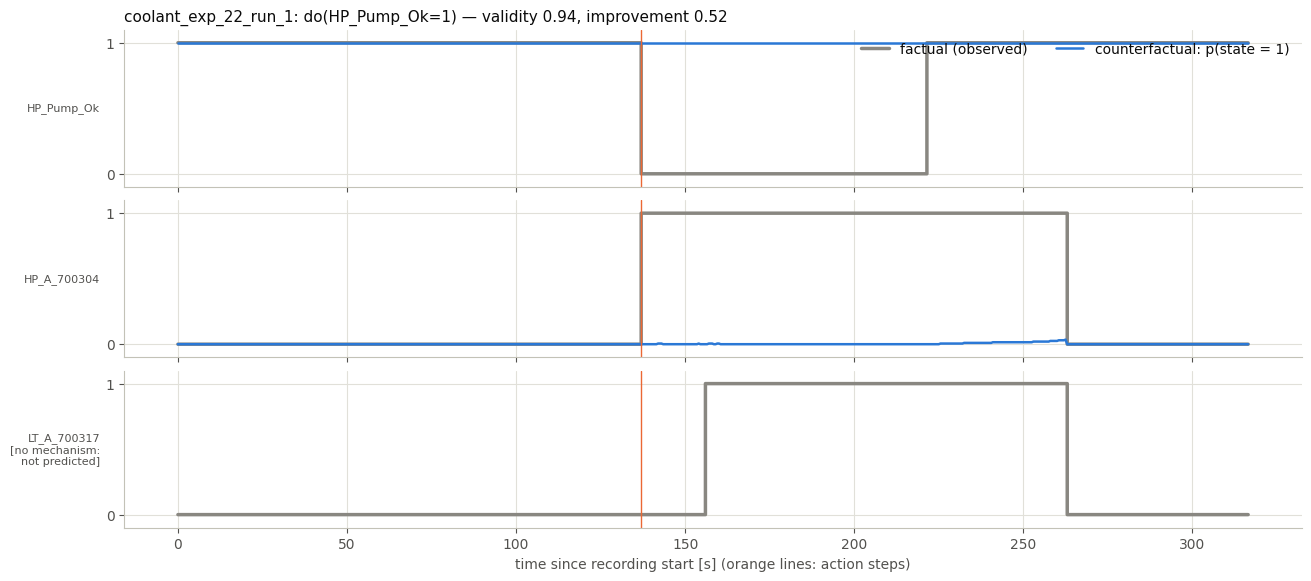

In [5]:
# figure 1: before vs after for one run: factual alarms and counterfactual alarm probability
fold = sorted(scms)[0]
rid = splits.loc[splits.fold == fold, 'recording_id'].iloc[0]
row = explanations.set_index('recording_id').loc[rid]
model = scms[fold]
series = sc.recording_series(view_data, rid)
ranking = rankings[rankings.recording_id == rid]
detection = dict(zip(ranking.variable, ranking.detection_step))
chosen = [a.split('=')[0].removeprefix('do(') for a in row.actions.split(' + ')]
actions = [itv.Action(v, itv.allowed_value(v), max(1, detection[v])) for v in chosen]
noise = model.abduct_noise(series, N_SAMPLES, np.random.default_rng(SEED))
fixed = {v: x for v, x in cfx.unrecorded_context(model, series).items() if v not in chosen}
world = model.simulate(cfx.initial_state(model, series), noise, interventions={a.variable: (a.value, a.start_step) for a in actions}, fixed=fixed)
shown = chosen + [a for a in ALARMS if a in series and not np.isnan(series[a]).all()]
t = np.arange(len(series[shown[0]])) * INTERVAL

fig, axes = plt.subplots(len(shown), 1, figsize=(13, 1.5 * len(shown) + 1.2), sharex=True, layout='constrained')
for ax, v in zip(axes, shown):
    ax.step(t, series[v], where='post', color=ev.INK['muted'], linewidth=2.5, label='factual (observed)')
    # an alarm without a mechanism estimate in this fold is not predicted at all
    supported = model.mechanisms[v].has_data
    if supported:
        ax.plot(t, world[v].mean(axis=0), color=ev.COLORS[0], linewidth=1.8, label='counterfactual: p(state = 1)')
    ax.set_ylabel(v if supported else v + '\n[no mechanism:\nnot predicted]', rotation=0, ha='right', va='center', fontsize=8)
    ax.set_ylim(-0.1, 1.1)
    ax.set_yticks([0, 1])
    for a in actions:
        ax.axvline(a.start_step * INTERVAL, color=ev.COLORS[1], linewidth=1)
axes[0].legend(loc='upper right', ncol=2)
axes[-1].set_xlabel('time since recording start [s] (orange lines: action steps)')
axes[0].set_title(f'{rid}: {row.actions} — validity {row.validity_probability:.2f}, improvement {row.improvement:.2f}')
ev.save_figure(fig, f'08_{SUBSYSTEM}_before_after')
plt.show()

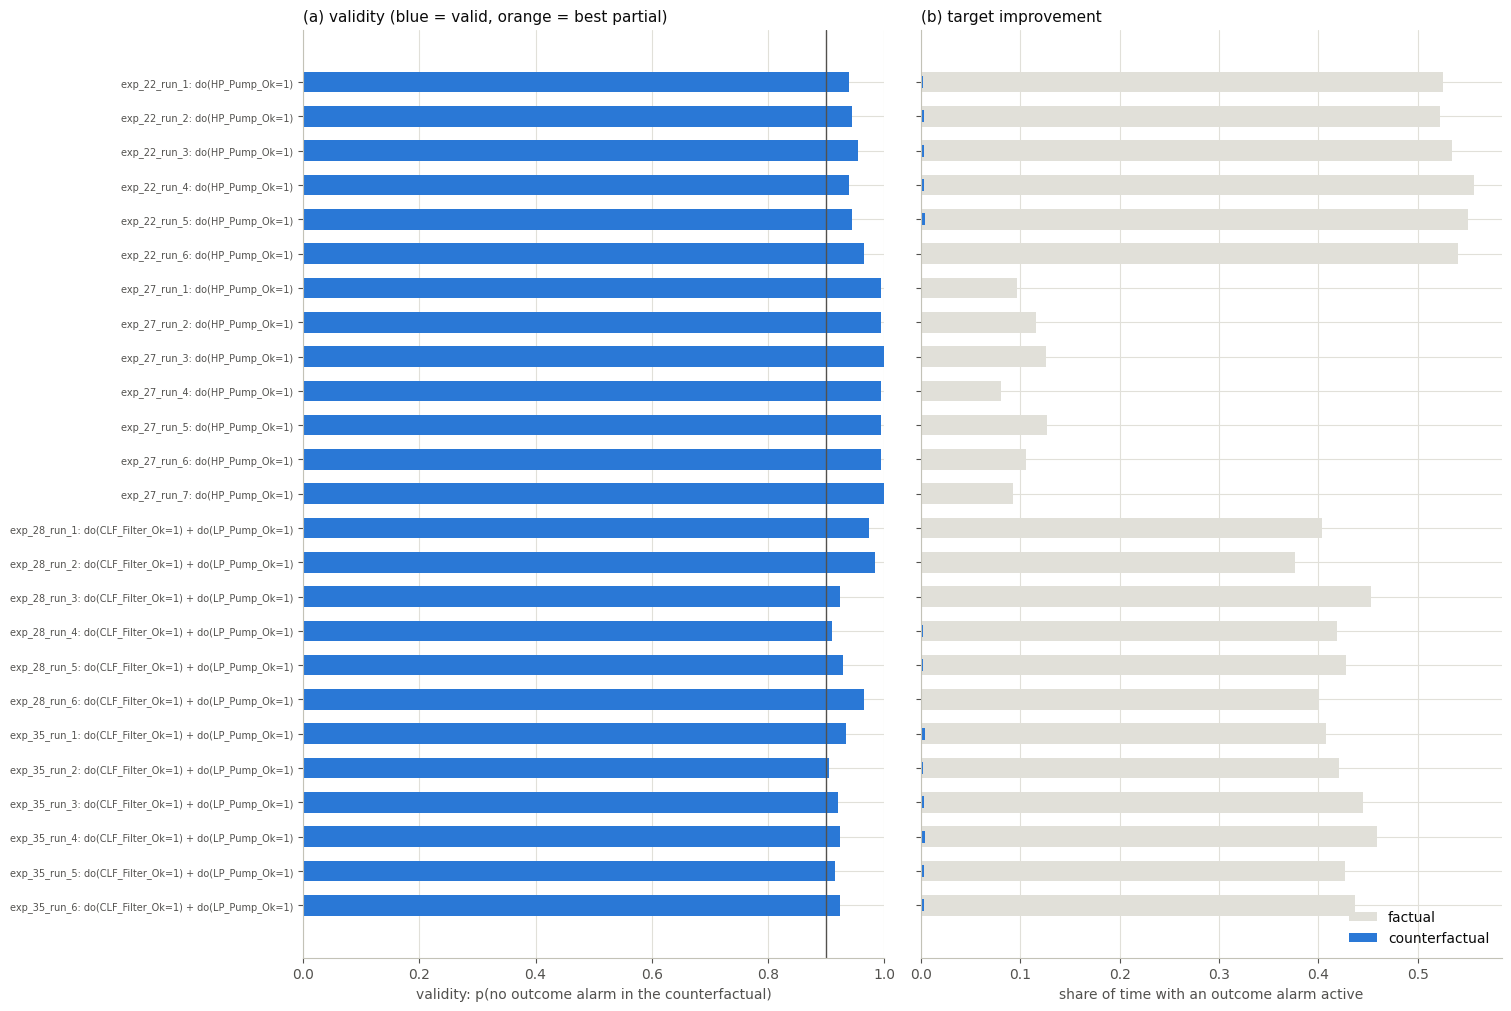

In [6]:
# figure 2: validity and improvement of the explanation of every run
d = explanations.sort_values(['fold', 'recording_id'])
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(15, 0.32 * len(d) + 2), sharey=True, layout='constrained')
colors = [ev.COLORS[0] if s == 'valid' else ev.COLORS[1] for s in d.status]
labels = [f'{r.removeprefix(SUBSYSTEM + "_")}: {a}' for r, a in zip(d.recording_id, d.actions)]
ax_a.barh(labels, d.validity_probability, color=colors, height=0.6)
ax_a.axvline(0.9, color=ev.INK['secondary'], linewidth=1)
ax_a.set_xlim(0, 1)
ax_a.set_xlabel('validity: p(no outcome alarm in the counterfactual)')
ax_a.invert_yaxis()
ax_b.barh(labels, d.factual_alarm_share, color=ev.INK['grid'], height=0.6, label='factual')
ax_b.barh(labels, d.counterfactual_alarm_share, color=ev.COLORS[0], height=0.35, label='counterfactual')
ax_b.set_xlabel('share of time with an outcome alarm active')
ax_b.legend(loc='lower right')
ax_a.set_title('(a) validity (blue = valid, orange = best partial)')
ax_b.set_title('(b) target improvement')
ax_a.tick_params(axis='y', labelsize=7)
ev.save_figure(fig, f'08_{SUBSYSTEM}_validity_improvement')
plt.show()

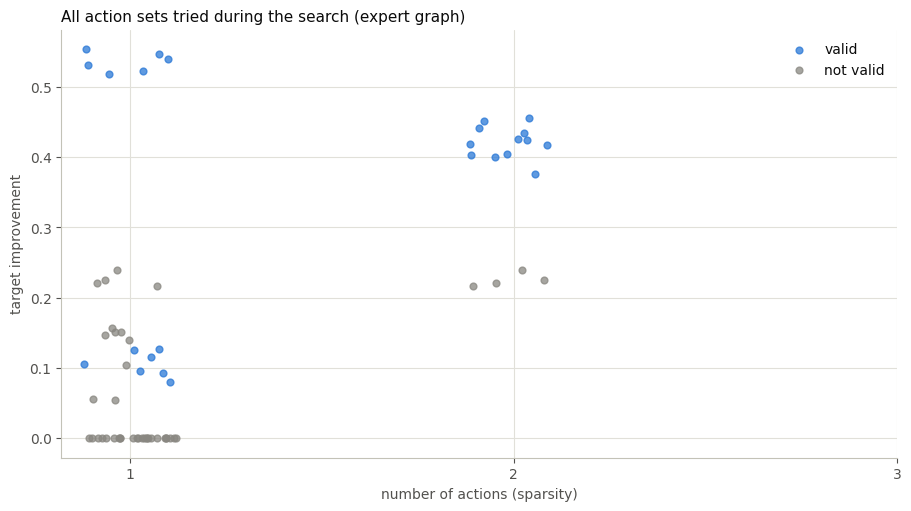

In [7]:
# figure 3: all tried action sets: improvement vs number of actions (the search space)
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
rng = np.random.default_rng(SEED)
for valid, color, label in [(True, ev.COLORS[0], 'valid'), (False, ev.INK['muted'], 'not valid')]:
    d = tried[tried.valid == valid]
    ax.scatter(d.n_actions + rng.uniform(-0.12, 0.12, len(d)), d.improvement, s=24, color=color, alpha=0.75, label=label)
ax.set_xticks([1, 2, 3])
ax.set_xlabel('number of actions (sparsity)')
ax.set_ylabel('target improvement')
ax.set_title('All action sets tried during the search (expert graph)')
ax.legend()
ev.save_figure(fig, f'08_{SUBSYSTEM}_search_space')
plt.show()

## 2. Robustness

Three checks, each re-evaluating the **same recommended action set**:
1. other abduction samples (other random seeds),
2. mechanisms refitted on bootstrap resamples of the training recordings,
3. other graphs, where we compare the recommendations themselves.

In [8]:
# robustness to noise samples and to refitted mechanisms
robust_rows = []
for _, r in explanations.iterrows():
    # runs without any actionable candidate have nothing to re-check
    if not isinstance(r.actions, str):
        continue
    fold, rid = r.fold, r.recording_id
    series = sc.recording_series(view_data, rid)
    ranking = rankings[rankings.recording_id == rid]
    detection = dict(zip(ranking.variable, ranking.detection_step))
    chosen = [a.split('=')[0].removeprefix('do(') for a in r.actions.split(' + ')]
    acts = [itv.Action(v, itv.allowed_value(v), max(1, detection[v])) for v in chosen]
    window = rca.analysis_window(series, ALARMS, INTERVAL)
    recorded = {v for v in series if not np.isnan(series[v]).all()}
    outcome = [o.strip() for o in r.outcome_alarms.split(',') if o.strip()]
    for seed in range(1, 6):
        res = cfx.counterfactual(scms[fold], series, acts, outcome, window[0], N_SAMPLES, np.random.default_rng(seed), recorded)
        robust_rows.append({'recording_id': rid, 'check': 'noise samples', 'validity_probability': res.validity_probability})
    train = data.fold_training_ids(splits, fold)
    for b in range(N_REFITS):
        sample = list(np.random.default_rng(100 + b).choice(train, size=len(train), replace=True))
        refit = sc.fit_scm(view_data, expert, sample, manipulated, INTERVAL)
        res = cfx.counterfactual(refit, series, acts, outcome, window[0], N_SAMPLES, np.random.default_rng(SEED), recorded)
        robust_rows.append({'recording_id': rid, 'check': 'refitted mechanisms', 'validity_probability': res.validity_probability})
robustness = pd.DataFrame(robust_rows)
ev.save_table(robustness, f'08_{SUBSYSTEM}_robustness')
robustness.groupby('check').validity_probability.describe().round(3)

,count,mean,std,min,25%,50%,75%,max
check,,,,,,,,
noise samples,125.0,0.954,0.031,0.885,0.93,0.95,0.985,1.0
refitted mechanisms,125.0,0.923,0.052,0.760,0.89,0.92,0.985,1.0


In [9]:
# recommendations with the discovered and the empty graph
explanations_by_graph = {'expert': explanations}
for g in ['discovered', 'empty']:
    _, rk, sm = rca_results[g]
    e, _ = cfx.explain_runs(sm, view_data, splits, rk, manipulated, ALARMS, INTERVAL, n_samples=N_SAMPLES, seed=SEED)
    explanations_by_graph[g] = e
    ev.save_table(e, f'08_{SUBSYSTEM}_explanations_{g}')
graph_summary = pd.DataFrame({g: summarize_explanations(e) for g, e in explanations_by_graph.items()}).T
ev.save_table(graph_summary.reset_index(names='graph'), f'08_{SUBSYSTEM}_summary_by_graph')

def action_set(text):
    return frozenset(a.split('=')[0].removeprefix('do(') for a in str(text).split(' + ')) if isinstance(text, str) else frozenset()
agreement = pd.DataFrame({g: e.set_index('recording_id').actions.map(action_set) for g, e in explanations_by_graph.items()})
for g in ['discovered', 'empty']:
    graph_summary.loc[g, 'same_recommendation_as_expert'] = (agreement[g] == agreement['expert']).mean()
graph_summary.round(3)

,runs,valid,mean_validity_probability,mean_improvement,mean_actions,mean_proximity_s,feasible,action_precision_vs_truth,action_recall_vs_truth,min_abduction_consistency,same_recommendation_as_expert
expert,25.0,1.0,0.955,0.36,1.48,85.18,1.0,1.0,0.66,1.0,NaN
discovered,25.0,1.0,0.956,0.36,1.48,85.18,1.0,1.0,0.66,1.0,1.00
empty,25.0,0.0,0.000,0.00,1.00,67.08,1.0,1.0,0.46,1.0,0.24


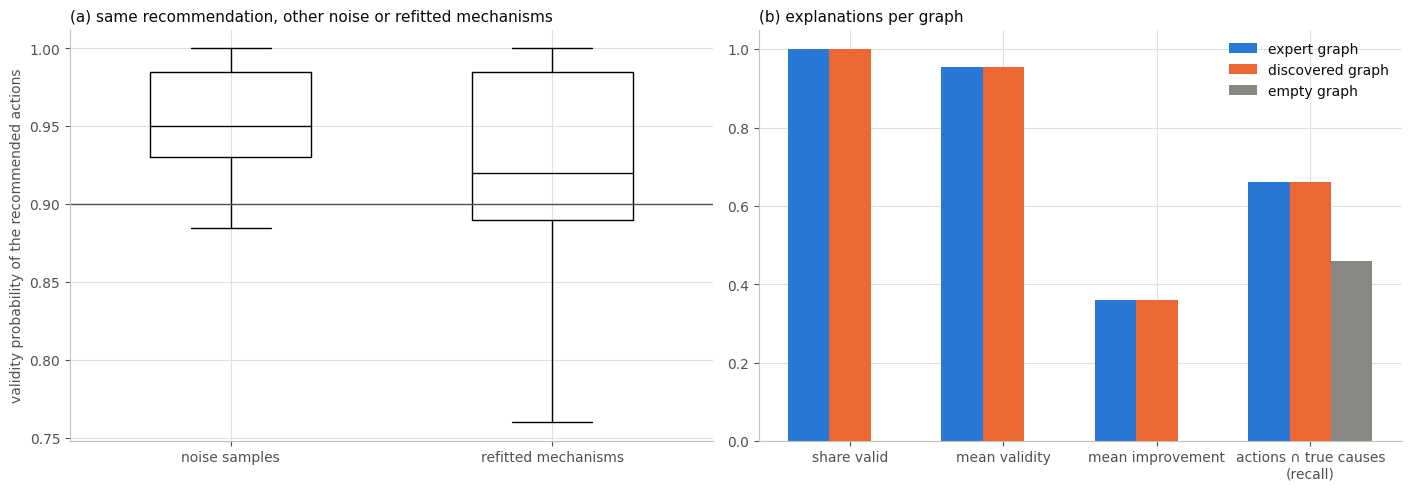

In [10]:
# figure 4: robustness overview
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 4.8), layout='constrained')
checks = ['noise samples', 'refitted mechanisms']
ax_a.boxplot([robustness.loc[robustness.check == c, 'validity_probability'] for c in checks], widths=0.5,
             medianprops={'color': ev.INK['primary']})
ax_a.set_xticks([1, 2], checks)
ax_a.axhline(0.9, color=ev.INK['secondary'], linewidth=1)
ax_a.set_ylabel('validity probability of the recommended actions')
ax_a.set_title('(a) same recommendation, other noise or refitted mechanisms')
metrics_shown = ['valid', 'mean_validity_probability', 'mean_improvement', 'action_recall_vs_truth']
x = np.arange(len(metrics_shown))
for k, g in enumerate(explanations_by_graph):
    ax_b.bar(x + (k - 1) * 0.27, graph_summary.loc[g, metrics_shown].astype(float), width=0.27, color=graph_colors[g], label=f'{g} graph')
ax_b.set_xticks(x, ['share valid', 'mean validity', 'mean improvement', 'actions ∩ true causes\n(recall)'])
ax_b.set_ylim(0, 1.05)
ax_b.set_title('(b) explanations per graph')
ax_b.legend(loc='upper right')
ev.save_figure(fig, f'08_{SUBSYSTEM}_robustness')
plt.show()

## 3. Findings

- **Explanations (expert graph, 25 held-out runs).**
  - Every run gets a **valid** explanation: mean validity 0.955, i.e. in 95.5% of the abducted worlds no supported alarm fires.
  - Mean target improvement is 0.36 of the window spent with an alarm active.
  - Mean sparsity is 1.48 actions, and every action is feasible.

  | Scenario | Explanation | Mean validity |
  |---|---|---|
  | exp_22 | do(`HP_Pump_Ok` = 1) | 0.95 |
  | exp_27 | do(`HP_Pump_Ok` = 1) | 1.00 |
  | exp_28 | do(`CLF_Filter_Ok` = 1) + do(`LP_Pump_Ok` = 1) | 0.95 |
  | exp_35 | do(`CLF_Filter_Ok` = 1) + do(`LP_Pump_Ok` = 1) | 0.92 |

- **Agreement with the true causes.**
  - Precision 1.00: no recommended action is wrong.
  - Recall 0.66: the missing third is exactly the causes whose alarm has no mechanism in that fold (`LT_Level_Ok`/`LT_A_700317`, `CLT_Level_lt_Min`/`CLT_A_700310`, `F_Filter_Ok`/`F_A_700313`).
  - The search only fixes what it can predict. These alarms are listed as unsupported instead of being claimed as prevented.
- **Abduction is exact.** Replaying the abducted noise without any action reproduces every recorded value of every supported variable (consistency 1.00).
- **Robustness.**
  - The validity of the chosen explanation varies little with other noise samples (mean 0.954, minimum 0.885).
  - It is somewhat lower with mechanisms refitted on bootstrap resamples (mean 0.923, minimum 0.76): a few refits fall just below the 0.9 threshold, so validity near the threshold should be read as approximate.
- **Graph dependence** — here the graph decides everything:
  - With the **discovered graph** the explanations are identical to the expert graph in all 25 runs (it found every cause → alarm edge that matters for the supported alarms).
  - With the **empty graph no run has a valid explanation** (validity 0.00, improvement 0.00). Without cause → alarm edges, no action changes an alarm.
- **Limits of the claim.**
  - These are individual counterfactuals *under the assumed monotone threshold noise*, for the simulated digital twin. There are no real counterfactual control runs, so they are not empirically validated.
  - They mean: "the model predicts these alarms would not have fired had these components been kept healthy from the detected break onward".
- *Thesis note:* together with notebook 06 this gives the central contrast of the thesis. *Finding* the root cause did not need the graph on coolant, but *explaining what to do about it* does.